In [39]:
low_memory = False
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns;sns.set()
from sklearn.datasets import make_blobs
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# DECISION TREES
One of the most intuitive and interpretable machine learning algorithms available to DS
- understanding the most intuitive and interpretable classifier: Decision trees

Decision trees mirror the way humans naturally make decisions by breaking down complex problems into simple yes and no questions...this makes them valuable for understanding how predictions are made...unlike black box algorithm where the decision making process is opaque.

- while we could manually construct such a tree using countless if else statements...the real power of decision trees lies in their ability to automatically learn these decision rules from data.
- ML algorithm can analyze datasets and determine the optimal sequence of questions to ask creating decision trees that can classify new,unseen examples with remarkable accuracy

# Key advantages of decision tree
- interpretability: the decision making process is transparent and easy to explain
- No assumptions : they dont require assumptions about data distribution
- handles mixed data types: can work with both numerical and categorical features
- feature selection : automatically indentifies the most important features

# Problem setting: HandWritten digit recongnition
- ML-MODEL: recognizing handwritten digits

for this model we will use the same digit dataset from sklearn we did before in logistic regression.Because:
- direct comparison: By using identical data we can make fair apples to apples comparisons between different algorithms
- consistent evaluation: we can apply the same metrics and evaluation criteria across different models
- understanding trade-offs : we will discover when decision trees might be preferred over logistic regression and vice versa

In [3]:
digits=datasets.load_digits()
dir(digits)
print("Image data shape",digits.data.shape)
print("Label data shape",digits.target.shape)

Image data shape (1797, 64)
Label data shape (1797,)


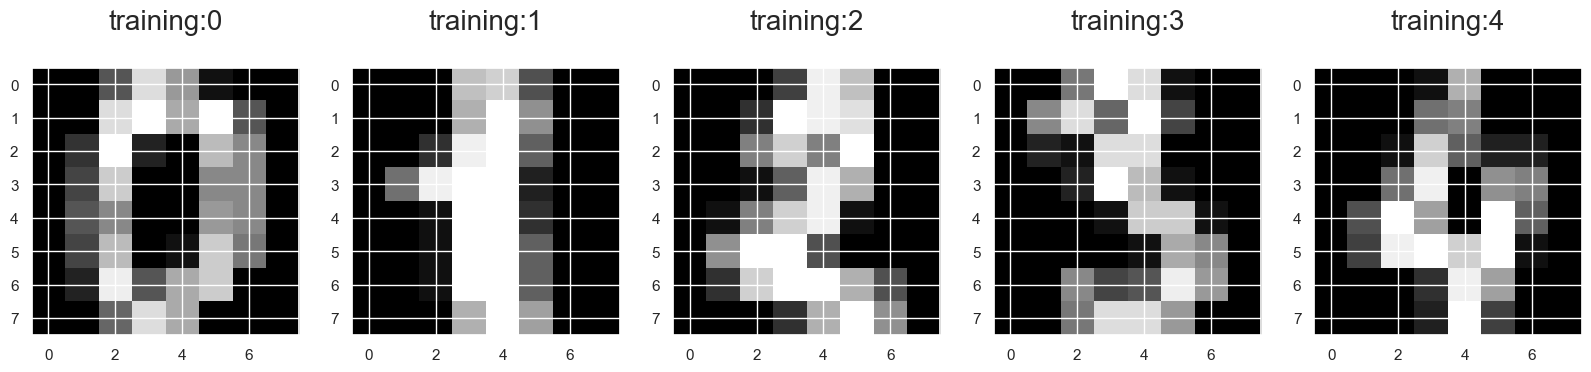

In [4]:
plt.figure(figsize=(20,4))
for index,(image,label) in enumerate(zip(digits.data[0:5],digits.target[0:5])):
    plt.subplot(1,5,index+1)
    plt.imshow(np.reshape(image,(8,8)),cmap=plt.cm.gray)
    plt.title('training:%i\n'%label,fontsize=20)

# understanding the decision trees
- Decision trees work by recursively partitioning the feature space into regions that are as homogeneous as possible with respect to the target variable

- decision trees work by asking a series of questions about the feature in the data..with each queation designed to split the data into groups that are as pure as possible(Containing mostly one class)

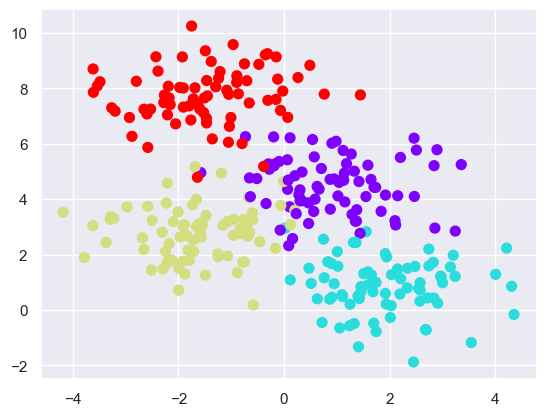

In [5]:
# a simple two dimensional classification problem where we can visualize exactly how the algorithm makes its decisions
X,y=make_blobs(n_samples=300,centers=4,random_state=0,cluster_std=1.0)
plt.scatter(X[:,0],X[:,1],c=y,s=50,cmap='rainbow')

# understanding the vis
- X-axis and Y-axis: These represent two independent variables(feature) in our dataset
- colors: each color represents a diff class(category) that we want to predict
- Goal: create a decision tree that can accurately classify new points based on their X and Y coordinates

this scatter plot shows four distint clusters of data points,each representing a different class. A human can easily see the patterns...but how does a computer algorithm learn to a distinguish between these gropus

# The decision tree learning process
- initial assessment: start with all data points mixed together
- Find the best split: identify the feature and theshold that best separates the classes
- create branches: Split the data into two groups based on this cirterion
- repeat recursively: Apply the same process to each new group
- stop when pure: continue untill each group contains mostly one class or meets stopping citeria

two commonly used criteria:
- gini impurity
- entropy and imformation gain


- Key insight: The algorithm draws line(splits) through feature space,with each line representing a decision boundary.These lines are always parrallel to the axes because each split considers only one feature at a time.

# Model implementation and training

In [6]:
# Data preparation
x_train,x_test,y_train,y_test = train_test_split(digits.data,digits.target,test_size=0.25,random_state=0)

In [7]:
# Model creation and training
tree = DecisionTreeClassifier()
tree_fit = tree.fit(x_train,y_train)

In [17]:
# Making prediction
prediction = tree_fit.predict(x_test)
print(prediction)

[2 3 2 6 6 7 1 9 8 0 2 8 6 6 6 6 4 0 5 8 8 7 8 4 7 5 4 9 2 9 4 7 6 8 9 4 3
 1 0 9 8 6 7 7 1 0 8 0 2 1 9 6 7 9 9 0 4 3 6 3 0 2 3 4 1 9 2 6 9 1 8 3 5 1
 2 8 2 2 9 7 2 3 6 0 9 2 7 5 1 2 5 9 3 1 4 7 4 8 5 8 5 8 2 5 9 0 7 2 4 7 2
 4 8 9 7 1 8 0 9 5 2 5 9 4 8 3 0 6 1 5 3 3 9 5 9 9 5 7 5 6 2 8 6 5 6 1 5 1
 5 9 9 1 3 3 6 1 4 9 8 7 6 7 6 5 6 0 8 8 9 8 6 1 0 4 1 6 3 8 6 7 4 3 6 2 9
 2 3 3 0 4 7 5 7 8 0 7 8 9 6 4 5 0 1 4 6 6 3 3 0 9 5 5 1 1 4 6 1 6 8 9 3 4
 9 3 7 6 2 3 2 1 6 9 3 6 3 2 2 0 7 6 1 1 9 7 2 9 8 5 5 7 5 2 9 7 2 4 5 5 9
 0 9 1 6 5 9 9 4 9 8 5 3 6 4 6 3 3 6 8 8 8 4 6 7 5 2 4 5 3 2 4 6 9 0 5 4 3
 4 6 2 9 0 2 7 2 0 9 6 2 4 2 0 7 1 8 5 9 8 2 8 4 3 4 2 6 4 1 5 2 0 8 2 1 3
 5 6 8 2 7 2 1 5 1 6 4 3 0 9 4 1 1 7 0 8 9 0 5 4 8 8 9 6 5 3 4 4 4 8 3 7 0
 9 6 3 5 2 3 0 8 3 3 1 3 3 0 0 1 6 0 7 7 6 2 0 4 4 2 3 7 3 9 8 6 8 5 6 2 2
 3 1 5 7 8 0 6 3 2 1 5 5 9 1 3 7 0 0 0 0 4 5 2 3 3 4 2 1 8 9 5 3 6 2 2 6 8
 1 7 5 5 1 9]


# Model evaluation
Evaluating decision trees performance requires examining multiple metrics to gain a complete understanding of how well oour model performs
- accuracy(foundation metrics)
- precision(class level performance)
- recall(class level performance)
- f1(class level performance)

In [18]:
# Model evaluation
print("accuracy_score =",tree_fit.score(x_test,y_test))

accuracy_score = 0.8488888888888889


In [19]:
print(classification_report(y_test,prediction))

              precision    recall  f1-score   support

           0       0.87      0.89      0.88        37
           1       0.90      0.84      0.87        43
           2       0.76      0.86      0.81        44
           3       0.73      0.78      0.75        45
           4       0.81      0.89      0.85        38
           5       0.87      0.85      0.86        48
           6       0.94      0.96      0.95        52
           7       1.00      0.77      0.87        48
           8       0.91      0.85      0.88        48
           9       0.74      0.79      0.76        47

    accuracy                           0.85       450
   macro avg       0.85      0.85      0.85       450
weighted avg       0.86      0.85      0.85       450



Text(0.5, 77.24999999999999, 'predicted')

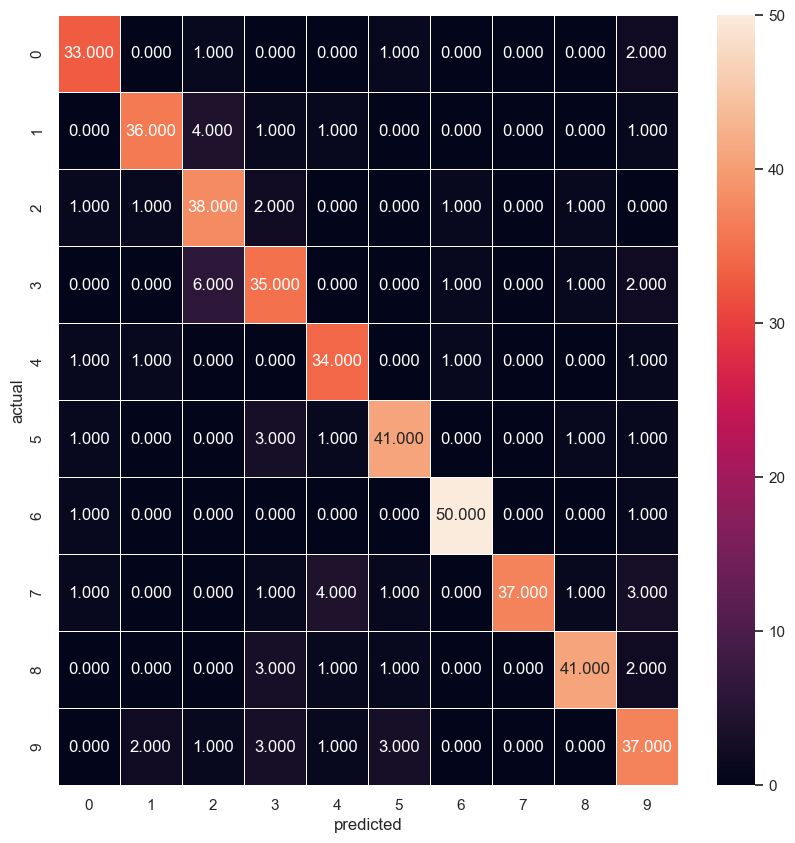

In [21]:
#Confusion matrix
plt.figure(figsize=(10,10))
sns.heatmap(metrics.confusion_matrix(y_test,prediction),annot=True,fmt=".3f",linewidth=.5)
plt.ylabel('actual')
plt.xlabel('predicted')

# Comparative confusion matrix analysis
- comparing confusion matrix between different algorithms can be challenging due ti their complexity...Lets create a comprehensive visual analysis that show the differennce between prediction pattern between logistic regression and decision trees

# implementation requirement
- Train both with a logistic regression and decision tree model on the same dataset
- generate confusion matrices for both models
- create a visualization showing the diff between the metrices
- interpret the result to understand algorithmic differences

In [22]:
from sklearn.linear_model import LogisticRegression

Logistic_model = LogisticRegression(max_iter=1000)
Logistic_model.fit(x_train,y_train)


LogisticRegression(max_iter=1000)

In [23]:
logistic_pred = Logistic_model.predict(x_test)
print(logistic_pred)

[2 8 2 6 6 7 1 9 8 5 2 8 6 6 6 6 1 0 5 8 8 7 8 4 7 5 4 9 2 9 4 7 6 8 9 4 3
 1 0 1 8 6 7 7 1 0 7 6 2 1 9 6 7 9 0 0 9 1 6 3 0 2 3 4 1 9 2 6 9 1 8 3 5 1
 2 8 2 2 9 7 2 3 6 0 5 3 7 5 1 2 9 9 3 1 4 7 4 8 5 8 5 5 2 5 9 0 7 1 4 7 3
 4 8 9 7 9 8 2 1 5 2 5 8 4 1 7 0 6 1 5 5 9 9 5 9 9 5 7 5 6 2 8 6 9 6 1 5 1
 5 9 9 1 5 3 6 1 8 9 8 7 6 7 6 5 6 0 8 8 9 9 6 1 0 4 1 6 3 8 6 7 4 9 6 3 0
 3 3 3 0 7 7 5 7 8 0 7 1 9 6 4 5 0 1 4 6 4 3 3 0 9 5 9 2 8 4 2 1 6 8 9 2 4
 9 3 7 6 2 3 3 1 6 9 3 6 3 3 2 0 7 6 1 1 9 7 2 7 8 5 5 7 5 3 3 7 2 7 5 5 7
 0 9 1 6 5 9 7 4 3 8 0 3 6 4 6 3 2 6 8 8 8 4 6 7 5 2 4 5 3 2 4 6 9 4 5 4 3
 4 6 2 9 0 1 7 2 0 9 6 0 4 2 0 7 9 8 5 7 8 2 8 4 3 7 2 6 9 9 5 1 0 8 2 8 9
 5 6 2 2 7 2 1 5 1 6 4 5 0 9 4 1 1 7 0 8 9 0 5 4 3 8 8 6 5 3 4 4 4 8 8 7 0
 9 6 3 5 2 3 0 8 8 3 1 3 3 0 0 4 6 0 7 7 6 2 0 4 4 2 3 7 1 9 8 6 8 5 6 2 2
 3 1 7 7 8 0 3 3 2 1 5 5 9 1 3 7 0 0 3 0 4 5 8 9 3 4 3 1 8 9 8 3 6 3 1 6 2
 1 7 5 5 1 9]


In [43]:
models = {"Logistic Regression": logistic_pred,"Decision Tree": prediction}

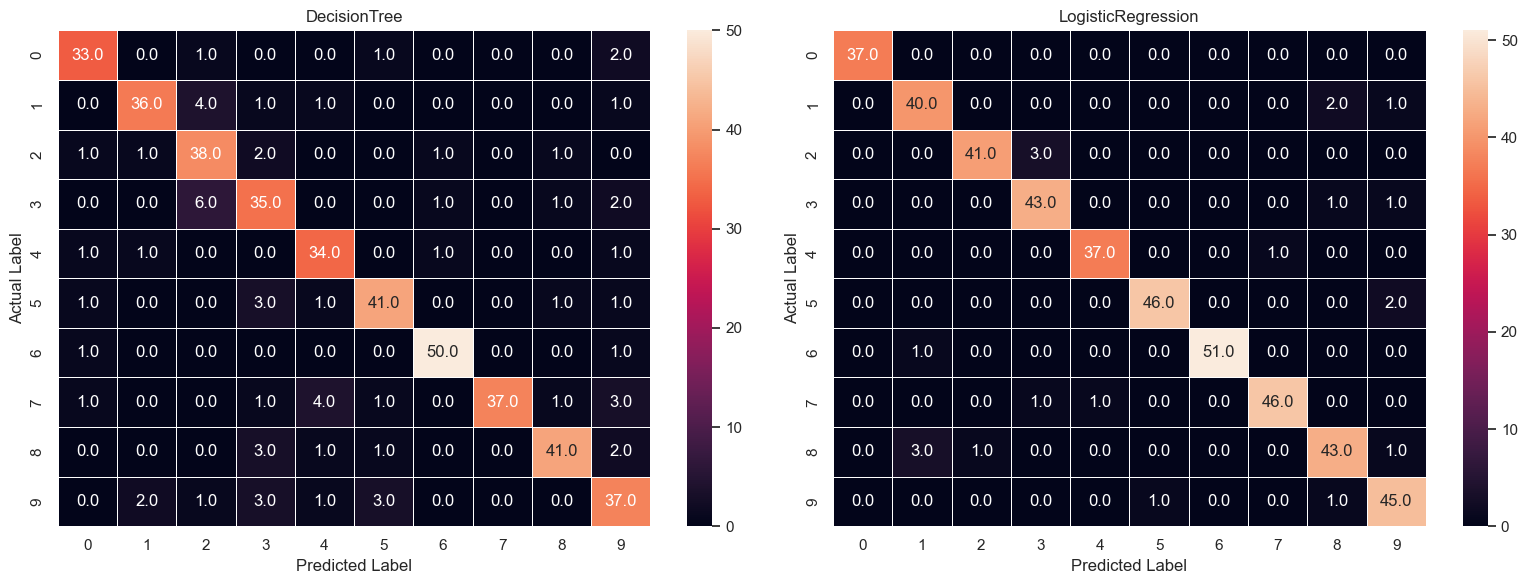

In [36]:
CM_DecisionTree=metrics.confusion_matrix(y_test,prediction)
CM_LogisticRegression = metrics.confusion_matrix(y_test,logistic_pred)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(CM_DecisionTree,annot=True,fmt=".1f",linewidth=.5,ax=axes[0])
sns.heatmap(CM_LogisticRegression,annot=True,fmt=".1f",linewidth=.5,ax=axes[1])
axes[0].set_title("DecisionTree")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")
axes[1].set_title("LogisticRegression")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")
plt.tight_layout()
plt.show()


In [44]:
# comparative analysis
results=[]
for i,j in models.items():
    results.append({"Model":i,"Accuracy": accuracy_score(y_test,j),"Precision":precision_score(y_test,j,average="weighted"),
                     "Recall":recall_score(y_test,j,average="weighted"),"f1_score":f1_score(y_test,j,average="weighted")})
df = pd.DataFrame(results).set_index("Model")
df


,Accuracy,Precision,Recall,f1_score
Model,,,,
Logistic Regression,0.953333,0.954191,0.953333,0.953519
Decision Tree,0.848889,0.856196,0.848889,0.850063


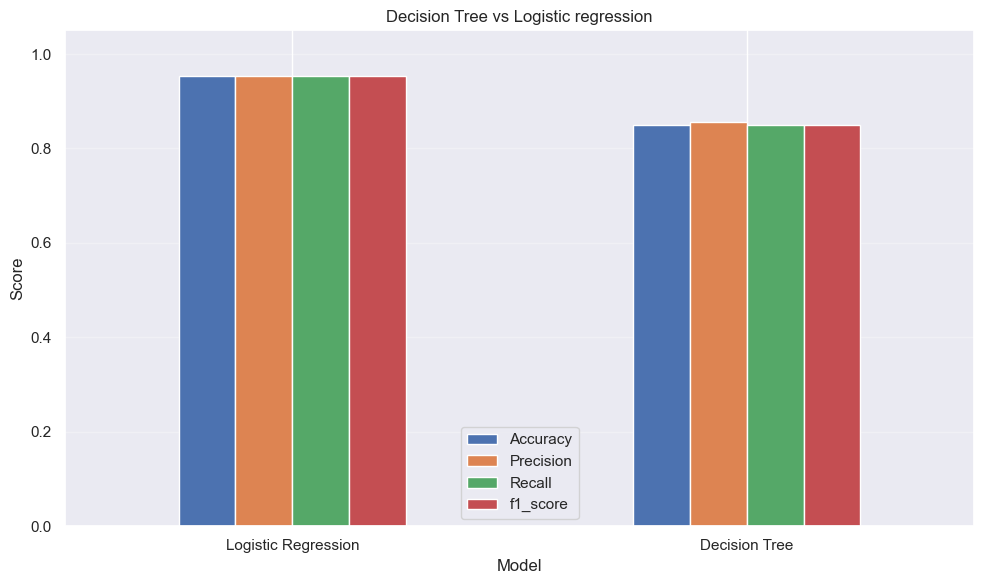

In [46]:
# Visualization
df.plot(kind="bar",figsize=(10,6))
plt.title("Decision Tree vs Logistic regression")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# logistic regression
- From the plot we can clearly see logistic regression is performing well than decision tree
- it has better model evalution scores
- it has correct prediction accroding to the test set
- Appears to be the stronger classifier for this dataset under your current settings.
# decision tree
- has lower performance accroding to the problem setting
- makes more classification errors